In [ ]:

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import json
import random
import shutil


Mounted at /content/drive


In [ ]:

# Cell 2: Dataset paths

DATA_DIR = Path("/content/drive/MyDrive/road_data")
IMAGES_DIR = DATA_DIR / "annotated-images"
SPLITS_FILE = DATA_DIR / "splits.json"

assert DATA_DIR.exists(), "Dataset folder not found"
assert IMAGES_DIR.exists(), "Image folder not found"
assert SPLITS_FILE.exists(), "splits.json not found"

print("Dataset path verified:", DATA_DIR)
print("Image/annotation files:", len(list(IMAGES_DIR.iterdir())))
print("Split file found:", SPLITS_FILE.name)


Dataset path verified: /content/drive/MyDrive/road_data
Image/annotation files: 1330
Split file found: splits.json


In [ ]:

# Cell 3: Load original train/test split

with open(SPLITS_FILE, "r") as f:
    splits = json.load(f)

train_xml = splits["train"]
test_xml = splits["test"]

print("Original training annotations:", len(train_xml))
print("Original test annotations:", len(test_xml))
print("Overlap:", len(set(train_xml) & set(test_xml)))


Original training annotations: 532
Original test annotations: 133
Overlap: 0


In [ ]:

# Cell 4: Create reproducible splits

SEED = 42
random.seed(SEED)

train_xml = sorted(train_xml)
random.shuffle(train_xml)

val_count = round(len(train_xml) * 0.20)

val_xml = sorted(train_xml[:val_count])
train_xml = sorted(train_xml[val_count:])
test_xml = sorted(test_xml)

print("Train:", len(train_xml))
print("Validation:", len(val_xml))
print("Test:", len(test_xml))

assert not (set(train_xml) & set(val_xml))
assert not (set(train_xml) & set(test_xml))
assert not (set(val_xml) & set(test_xml))

print("No overlapping annotation filenames.")


Train: 426
Validation: 106
Test: 133
No overlapping annotation filenames.


In [ ]:

# Cell 5: Create shared dataset directory structure

OUTPUT_DIR = Path("/content/drive/MyDrive/road_data_shared")

for split in ["train", "val", "test"]:
    (OUTPUT_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUTPUT_DIR / "annotations" / split).mkdir(parents=True, exist_ok=True)

print("Shared dataset folder:", OUTPUT_DIR)
print("Directory structure created successfully.")

for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_dir():
        print(path.relative_to(OUTPUT_DIR))


Shared dataset folder: /content/drive/MyDrive/road_data_shared
Directory structure created successfully.
annotations
annotations/test
annotations/train
annotations/val
images
images/test
images/train
images/val


In [ ]:

# Cell 6: Copy image/XML pairs into shared split folders

split_lists = {
    "train": train_xml,
    "val": val_xml,
    "test": test_xml
}

missing_files = []

for split, xml_files in split_lists.items():
    for xml_name in xml_files:
        image_name = Path(xml_name).with_suffix(".jpg").name

        src_xml = IMAGES_DIR / xml_name
        src_image = IMAGES_DIR / image_name

        if not src_xml.exists():
            missing_files.append(str(src_xml))
            continue

        if not src_image.exists():
            missing_files.append(str(src_image))
            continue

        shutil.copy2(src_image, OUTPUT_DIR / "images" / split / image_name)
        shutil.copy2(src_xml, OUTPUT_DIR / "annotations" / split / xml_name)

print("Copy operation finished.")
print("Missing files:", len(missing_files))

if missing_files:
    print("First missing files:")
    for filename in missing_files[:20]:
        print(filename)
else:
    print("All image/XML pairs copied successfully.")

for split in split_lists:
    image_count = len(list((OUTPUT_DIR / "images" / split).glob("*.jpg")))
    xml_count = len(list((OUTPUT_DIR / "annotations" / split).glob("*.xml")))
    print(f"{split}: {image_count} images, {xml_count} XML annotations")


Copy operation finished.
Missing files: 0
All image/XML pairs copied successfully.
train: 426 images, 426 XML annotations
val: 106 images, 106 XML annotations
test: 133 images, 133 XML annotations


In [ ]:

# Cell 7: Save split manifest

manifest = {
    "seed": SEED,
    "source_split": "Original 80/20 split; original test set preserved",
    "train": train_xml,
    "val": val_xml,
    "test": test_xml
}

manifest_path = OUTPUT_DIR / "split_manifest.json"

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2)

print("Manifest saved:", manifest_path)
print("Train:", len(manifest["train"]))
print("Validation:", len(manifest["val"]))
print("Test:", len(manifest["test"]))


Manifest saved: /content/drive/MyDrive/road_data_shared/split_manifest.json
Train: 426
Validation: 106
Test: 133


In [ ]:

# Cell 8: Verify shared dataset

for split in ["train", "val", "test"]:
    img_dir = OUTPUT_DIR / "images" / split
    ann_dir = OUTPUT_DIR / "annotations" / split

    images = {p.stem for p in img_dir.glob("*.jpg")}
    annotations = {p.stem for p in ann_dir.glob("*.xml")}

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Annotations:", len(annotations))
    print("Images without XML:", len(images - annotations))
    print("XML without image:", len(annotations - images))

    assert images == annotations, f"Mismatch found in {split} split!"

print("\nSUCCESS: All splits have matching image/XML pairs.")



TRAIN
Images: 426
Annotations: 426
Images without XML: 0
XML without image: 0

VAL
Images: 106
Annotations: 106
Images without XML: 0
XML without image: 0

TEST
Images: 133
Annotations: 133
Images without XML: 0
XML without image: 0

SUCCESS: All splits have matching image/XML pairs.


In [ ]:

from pathlib import Path
import json
import xml.etree.ElementTree as ET

DATA_DIR = Path("/content/drive/MyDrive/road_data_shared")
MANIFEST = DATA_DIR / "split_manifest.json"

assert MANIFEST.exists(), "Split manifest not found"

with open(MANIFEST, "r") as f:
    manifest = json.load(f)

for split in ["train", "val", "test"]:
    img_dir = DATA_DIR / "images" / split
    ann_dir = DATA_DIR / "annotations" / split

    print(
        split,
        "| images:", len(list(img_dir.glob("*.jpg"))),
        "| XML:", len(list(ann_dir.glob("*.xml"))),
        "| manifest entries:", len(manifest[split])
    )


train | images: 426 | XML: 426 | manifest entries: 426
val | images: 106 | XML: 106 | manifest entries: 106
test | images: 133 | XML: 133 | manifest entries: 133


In [ ]:

# Inspect img-415.xml and its corresponding image

xml_file = DATA_DIR / "annotations" / "train" / "img-415.xml"
img_file = DATA_DIR / "images" / "train" / "img-415.jpg"

root = ET.parse(xml_file).getroot()
size = root.find("size")

print("XML filename:", root.findtext("filename"))
print("XML dimensions:", size.findtext("width"), "x", size.findtext("height"))

from PIL import Image

with Image.open(img_file) as img:
    print("Actual image dimensions:", img.width, "x", img.height)

print("\nBounding boxes:")
for i, obj in enumerate(root.findall("object"), start=1):
    box = obj.find("bndbox")
    coords = {
        key: box.findtext(key)
        for key in ["xmin", "ymin", "xmax", "ymax"]
    }
    print(f"Object {i}: class={obj.findtext('name')}, box={coords}")


XML filename: img-415.jpg
XML dimensions: 400 x 300
Actual image dimensions: 400 x 300

Bounding boxes:
Object 1: class=pothole, box={'xmin': '150', 'ymin': '138', 'xmax': '261', 'ymax': '184'}
Object 2: class=pothole, box={'xmin': '84', 'ymin': '79', 'xmax': '158', 'ymax': '97'}
Object 3: class=pothole, box={'xmin': '273', 'ymin': '164', 'xmax': '273', 'ymax': '165'}


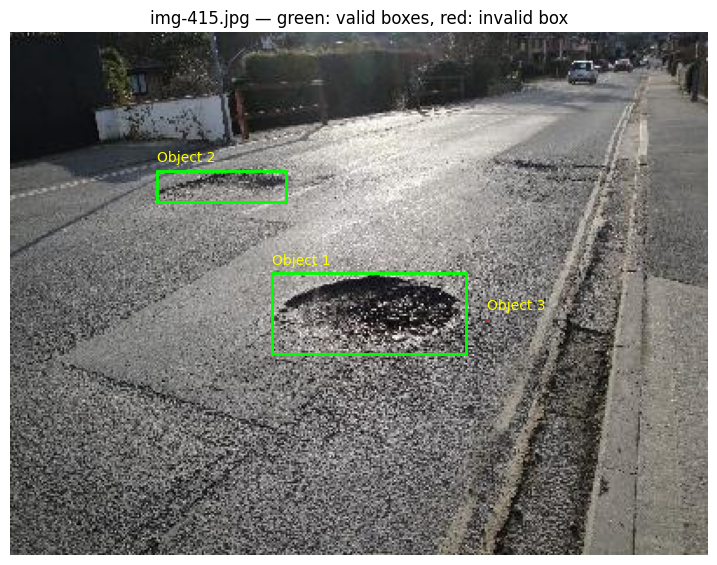

In [ ]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches

with Image.open(img_file) as img:
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.imshow(img)

    for i, obj in enumerate(root.findall("object"), start=1):
        box = obj.find("bndbox")
        xmin = float(box.findtext("xmin"))
        ymin = float(box.findtext("ymin"))
        xmax = float(box.findtext("xmax"))
        ymax = float(box.findtext("ymax"))

        rect = patches.Rectangle(
            (xmin, ymin),
            xmax - xmin,
            ymax - ymin,
            linewidth=2,
            edgecolor="red" if xmin == xmax or ymin == ymax else "lime",
            facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(xmin, max(0, ymin - 5), f"Object {i}", color="yellow")

    ax.set_title("img-415.jpg — green: valid boxes, red: invalid box")
    ax.axis("off")
    plt.show()


In [ ]:

# Count invalid bounding boxes across all splits

invalid_boxes = []

for split in ["train", "val", "test"]:
    ann_dir = DATA_DIR / "annotations" / split

    for xml_file in ann_dir.glob("*.xml"):
        root = ET.parse(xml_file).getroot()
        size = root.find("size")

        if size is None:
            continue

        width = int(size.findtext("width"))
        height = int(size.findtext("height"))

        for i, obj in enumerate(root.findall("object"), start=1):
            box = obj.find("bndbox")

            try:
                xmin = float(box.findtext("xmin"))
                ymin = float(box.findtext("ymin"))
                xmax = float(box.findtext("xmax"))
                ymax = float(box.findtext("ymax"))

                if not (
                    0 <= xmin < xmax <= width
                    and 0 <= ymin < ymax <= height
                ):
                    invalid_boxes.append(
                        (split, xml_file.name, i,
                         (xmin, ymin, xmax, ymax))
                    )
            except (AttributeError, TypeError, ValueError):
                invalid_boxes.append(
                    (split, xml_file.name, i, "Missing/invalid coordinates")
                )

print("Invalid boxes found:", len(invalid_boxes))
for item in invalid_boxes[:30]:
    print(item)


Invalid boxes found: 1
('train', 'img-415.xml', 3, (273.0, 164.0, 273.0, 165.0))


In [ ]:

# Cell 3: Convert XML annotations to YOLO format and log invalid boxes

YOLO_DIR = DATA_DIR / "yolo_dataset"
invalid_report = []

for split in ["train", "val", "test"]:
    label_dir = YOLO_DIR / "labels" / split
    label_dir.mkdir(parents=True, exist_ok=True)

    for xml_file in (DATA_DIR / "annotations" / split).glob("*.xml"):
        root = ET.parse(xml_file).getroot()
        size = root.find("size")
        img_w = int(size.findtext("width"))
        img_h = int(size.findtext("height"))

        lines = []

        for i, obj in enumerate(root.findall("object"), start=1):
            name = obj.findtext("name", "").strip()
            if name != "pothole":
                raise ValueError(
                    f"Unexpected class '{name}' in {xml_file.name}"
                )

            box = obj.find("bndbox")
            try:
                xmin = float(box.findtext("xmin"))
                ymin = float(box.findtext("ymin"))
                xmax = float(box.findtext("xmax"))
                ymax = float(box.findtext("ymax"))
            except (AttributeError, TypeError, ValueError):
                invalid_report.append(
                    (split, xml_file.name, i, "Missing/invalid coordinates")
                )
                continue

            if not (
                0 <= xmin < xmax <= img_w
                and 0 <= ymin < ymax <= img_h
            ):
                invalid_report.append(
                    (split, xml_file.name, i,
                     f"Invalid box: {(xmin, ymin, xmax, ymax)}")
                )
                continue

            xc = ((xmin + xmax) / 2) / img_w
            yc = ((ymin + ymax) / 2) / img_h
            bw = (xmax - xmin) / img_w
            bh = (ymax - ymin) / img_h

            lines.append(f"0 {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")

        (label_dir / f"{xml_file.stem}.txt").write_text(
            "\n".join(lines) + ("\n" if lines else "")
        )

print("YOLO label conversion complete.")
print("Invalid annotations logged:", len(invalid_report))
for issue in invalid_report:
    print(issue)


YOLO label conversion complete.
Invalid annotations logged: 1
('train', 'img-415.xml', 3, 'Invalid box: (273.0, 164.0, 273.0, 165.0)')


In [ ]:

# Cell 4: Create YOLO data.yaml

import yaml

config = {
    "path": str(DATA_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {0: "pothole"},
    "nc": 1
}

yaml_path = YOLO_DIR / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print(yaml_path.read_text())


path: /content/drive/MyDrive/road_data_shared
train: images/train
val: images/val
test: images/test
names:
  0: pothole
nc: 1



In [ ]:

# Cell 5: Verify YOLO image-label pairs

for split in ["train", "val", "test"]:
    img_dir = DATA_DIR / "images" / split
    label_dir = YOLO_DIR / "labels" / split

    images = {p.stem for p in img_dir.glob("*.jpg")}
    labels = {p.stem for p in label_dir.glob("*.txt")}

    box_count = sum(
        len(p.read_text().splitlines())
        for p in label_dir.glob("*.txt")
    )

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Label files:", len(labels))
    print("Images missing labels:", len(images - labels))
    print("Labels missing images:", len(labels - images))
    print("Valid bounding boxes:", box_count)

    assert images == labels, f"Image-label mismatch in {split}"

print("\nAll images have matching YOLO label files.")



TRAIN
Images: 426
Label files: 426
Images missing labels: 0
Labels missing images: 0
Valid bounding boxes: 1172

VAL
Images: 106
Label files: 106
Images missing labels: 0
Labels missing images: 0
Valid bounding boxes: 268

TEST
Images: 133
Label files: 133
Images missing labels: 0
Labels missing images: 0
Valid bounding boxes: 299

All images have matching YOLO label files.


In [ ]:

# Cell 6: Validate YOLO label format and normalized coordinates

errors = []

for split in ["train", "val", "test"]:
    label_dir = YOLO_DIR / "labels" / split

    for label_file in label_dir.glob("*.txt"):
        for line_no, line in enumerate(
            label_file.read_text().splitlines(), start=1
        ):
            parts = line.split()

            if len(parts) != 5:
                errors.append(
                    f"{split}/{label_file.name}:{line_no} - expected 5 values"
                )
                continue

            try:
                class_id = int(parts[0])
                coords = [float(v) for v in parts[1:]]

                if class_id != 0:
                    errors.append(f"{label_file.name}: unexpected class ID")

                if not all(0 < v < 1 for v in coords):
                    errors.append(
                        f"{label_file.name}:{line_no} - invalid normalized coordinates"
                    )
            except ValueError:
                errors.append(
                    f"{label_file.name}:{line_no} - non-numeric values"
                )

print("YOLO label errors:", len(errors))
for error in errors[:20]:
    print(error)

if not errors:
    print("SUCCESS: All YOLO labels have valid format and normalized coordinates.")


YOLO label errors: 0
SUCCESS: All YOLO labels have valid format and normalized coordinates.


In [ ]:

# Cell 7: Save annotation issue report

report_path = YOLO_DIR / "annotation_issues.json"

report = {
    "total_invalid_boxes": len(invalid_report),
    "issues": [
        {
            "split": split,
            "file": filename,
            "object_index": obj_index,
            "details": details
        }
        for split, filename, obj_index, details in invalid_report
    ]
}

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print("Issue report saved:", report_path)
print("Invalid boxes documented:", report["total_invalid_boxes"])


Issue report saved: /content/drive/MyDrive/road_data_shared/yolo_dataset/annotation_issues.json
Invalid boxes documented: 1


In [ ]:

# Cell 8: Save dataset summary

summary = {
    "dataset": "Annotated Potholes Image Dataset",
    "classes": {"0": "pothole"},
    "split_seed": manifest["seed"],
    "images": {},
    "valid_bounding_boxes": {},
    "invalid_boxes_documented": len(invalid_report)
}

for split in ["train", "val", "test"]:
    summary["images"][split] = len(
        list((DATA_DIR / "images" / split).glob("*.jpg"))
    )
    summary["valid_bounding_boxes"][split] = sum(
        len(p.read_text().splitlines())
        for p in (YOLO_DIR / "labels" / split).glob("*.txt")
    )

summary_path = YOLO_DIR / "dataset_summary.json"

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))
print("\nSummary saved:", summary_path)


{
  "dataset": "Annotated Potholes Image Dataset",
  "classes": {
    "0": "pothole"
  },
  "split_seed": 42,
  "images": {
    "train": 426,
    "val": 106,
    "test": 133
  },
  "valid_bounding_boxes": {
    "train": 1172,
    "val": 268,
    "test": 299
  },
  "invalid_boxes_documented": 1
}

Summary saved: /content/drive/MyDrive/road_data_shared/yolo_dataset/dataset_summary.json


In [ ]:

# Cell 9: Place YOLO labels beside the images directory

import shutil

for split in ["train", "val", "test"]:
    source = YOLO_DIR / "labels" / split
    destination = DATA_DIR / "labels" / split

    destination.mkdir(parents=True, exist_ok=True)

    for label_file in source.glob("*.txt"):
        shutil.copy2(label_file, destination / label_file.name)

    print(
        f"{split}:",
        len(list(destination.glob("*.txt"))),
        "labels ready"
    )

print("\nYOLO dataset structure is ready.")


train: 426 labels ready
val: 106 labels ready
test: 133 labels ready

YOLO dataset structure is ready.


In [ ]:

# Cell 10: Final YOLO dataset verification

for split in ["train", "val", "test"]:
    images = {
        p.stem for p in (DATA_DIR / "images" / split).glob("*.jpg")
    }
    labels = {
        p.stem for p in (DATA_DIR / "labels" / split).glob("*.txt")
    }

    print(
        f"{split}: images={len(images)}, labels={len(labels)}, "
        f"missing_labels={len(images - labels)}, "
        f"orphan_labels={len(labels - images)}"
    )

    assert images == labels, f"Mismatch in {split}"

assert yaml_path.exists(), "data.yaml missing"

print("\ndata.yaml exists:", yaml_path)
print("SUCCESS: Image-label matching verified for all splits.")


train: images=426, labels=426, missing_labels=0, orphan_labels=0
val: images=106, labels=106, missing_labels=0, orphan_labels=0
test: images=133, labels=133, missing_labels=0, orphan_labels=0

data.yaml exists: /content/drive/MyDrive/road_data_shared/yolo_dataset/data.yaml
SUCCESS: Image-label matching verified for all splits.
